# 04 - Placar das 3 configurações, 5 erros reais e demonstração de alucinações
**Requisitos 04, 06 e 07.** Mesmo modelo, mesmos 50 casos, três configurações:
- **A. Sem contexto:** modelo base, sem a base de conhecimento.
- **B. RAG simples:** busca + limiar + modelo base.
- **C. RAG + LoRA:** busca + limiar + modelo com o adaptador.

In [1]:
# Setup (Colab: Ambiente de execução > Alterar tipo > GPU T4). Local: só rode a partir da raiz do repositório.
import os, sys, subprocess
REPO = "https://github.com/melo-zz/calcada-livre-genai.git"   # <- troque pelo link do repositório público da equipe
if os.path.exists("/content"):                                  # estamos no Colab
    if not os.path.exists("/content/repo"):
        subprocess.run(["git", "clone", REPO, "/content/repo"], check=True)
    os.chdir("/content/repo")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("pasta de trabalho:", os.getcwd())

pasta de trabalho: /content/repo


In [2]:
%pip install -q -r requirements.txt
%pip uninstall -y -q torchao   # o torchao pré-instalado no Colab é antigo demais para o peft

In [3]:
import random, numpy as np
SEED = 42
random.seed(SEED); np.random.seed(SEED)
try:
    import torch; torch.manual_seed(SEED)
except ImportError:
    pass

In [4]:
import json, os, time
import pandas as pd
from src.kb import carregar_trechos
from avaliacao.casos import carregar
from src.retrieval import Retriever
from src.llm import HFGen
from src.pipeline import Assistente
from src.avaliacao import avaliar_caso, placar, classificar_erro, CAUSAS
os.makedirs(".cache", exist_ok=True)
trechos, casos = carregar_trechos("base/trechos.jsonl"), carregar()
ids = {t["id"] for t in trechos}
r = Retriever(trechos, cache=".cache/emb.npy")
# Estes dois arquivos são gerados pelos notebooks 02 e 03 e não vão para o GitHub; se faltarem (sessão nova do Colab), recriamos aqui.
from src.retrieval import escolher_limiar
if not os.path.exists("avaliacao/limiar.json"):
    res = escolher_limiar(casos, r)
    json.dump({"limiar": res["limiar"], "acuracia_balanceada": res["acuracia_balanceada"]}, open("avaliacao/limiar.json", "w"), indent=2)
limiar = json.load(open("avaliacao/limiar.json"))["limiar"]
if not os.path.exists("modelo/lora_qwen15b"):            # mesmo treino do notebook 03 (~12 min na T4)
    from src.lora_data import construir, salvar
    from src.treino_lora import treinar
    exemplos = construir(trechos, retriever=r, n_consta=360, n_nc=120, seed=SEED)
    salvar(exemplos)
    treinar(exemplos, saida="modelo/lora_qwen15b", epocas=2, seed=SEED)
gen = HFGen(adapter="modelo/lora_qwen15b")
aB = Assistente(r, lambda m: gen.gerar(m, usar_adapter=False), limiar)
aC = Assistente(r, lambda m: gen.gerar(m, usar_adapter=True), limiar)S
CONFIGS = {"A. Sem contexto": lambda q: aB.perguntar(q, usar_contexto=False),
           "B. RAG simples": lambda q: aB.perguntar(q),
           "C. RAG + LoRA": lambda q: aC.perguntar(q)}
print("limiar usado:", limiar, "| casos:", len(casos))

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (19 outputs left out)

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820
480 exemplos de treino (0 descartados por tamanho)


Step,Training Loss
5,0.096165
10,0.038055
15,0.028386
20,0.016812
25,0.019323
30,0.014298
35,0.010000
40,0.007871
45,0.008627
50,0.007281


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

limiar usado: 0.862956166267395 | casos: 51


In [5]:
saidas, resultados = {}, {}
for nome, f in CONFIGS.items():
    t0 = time.time()
    saidas[nome] = [f(c["pergunta"]) for c in casos]
    resultados[nome] = [avaliar_caso(c, s, ids) for c, s in zip(casos, saidas[nome])]
    print(nome, f"{time.time()-t0:.0f}s")
    with open(f"avaliacao/saidas_{nome[0]}.jsonl", "w", encoding="utf-8") as fh:
        for c, s in zip(casos, saidas[nome]):
            fh.write(json.dumps({"pergunta": c["pergunta"], "saida": {k: s[k] for k in ("resposta", "fontes", "consta", "json_valido", "caminho", "bruto")}}, ensure_ascii=False) + "\n")

A. Sem contexto 214s
B. RAG simples 158s
C. RAG + LoRA 293s


## Placar
Definições das métricas: veja `src/avaliacao.py`. *Acerto* é conservador (exige termo-chave do gabarito); *alucinação* conta afirmar o que não consta, citar fonte inexistente ou afirmar sem o termo-chave.

,configuracao,casos,json_valido_%,acerto_%,recusa_correta_%,citacao_correta_%,citacao_inventada_%,alucinacao_%
0,A. Sem contexto,51,88.2,17.1,10.0,0.0,88.2,88.2
1,B. RAG simples,51,95.1,70.7,90.0,70.7,0.0,19.6
2,C. RAG + LoRA,51,100.0,53.7,100.0,56.1,0.0,19.6


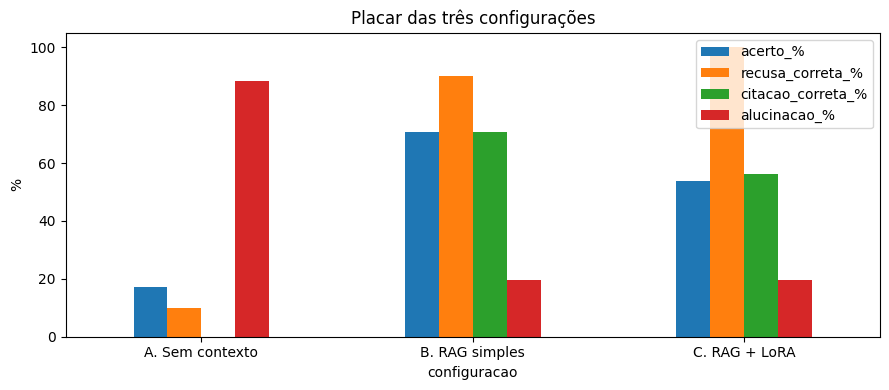

In [6]:
p = placar(resultados)
display(p)
p.to_csv("avaliacao/placar.csv", index=False)
open("avaliacao/placar.md", "w", encoding="utf-8").write(p.to_markdown(index=False))
import matplotlib.pyplot as plt
cols = ["acerto_%", "recusa_correta_%", "citacao_correta_%", "alucinacao_%"]
p.set_index("configuracao")[cols].plot(kind="bar", figsize=(9, 4)); plt.ylabel("%"); plt.xticks(rotation=0)
plt.title("Placar das três configurações"); plt.tight_layout(); plt.savefig("avaliacao/placar.png", dpi=150); plt.show()

## Interpretação automática (revise e ajuste o texto no relatório)

In [7]:
a, b, c = [p.set_index("configuracao").loc[k] for k in p.configuracao]
txt = []
txt.append(f"- **Acerto:** {a['acerto_%']}% sem contexto, {b['acerto_%']}% com RAG e {c['acerto_%']}% com RAG + LoRA.")
txt.append(f"- **Alucinação:** caiu de {a['alucinacao_%']}% (sem contexto) para {b['alucinacao_%']}% (RAG) e {c['alucinacao_%']}% (RAG + LoRA).")
txt.append(f"- **Recusa correta ('não consta'):** {a['recusa_correta_%']}% → {b['recusa_correta_%']}% → {c['recusa_correta_%']}%.")
txt.append(f"- **Citação correta:** {a['citacao_correta_%']}% → {b['citacao_correta_%']}% → {c['citacao_correta_%']}%; citação inventada: {a['citacao_inventada_%']}% → {b['citacao_inventada_%']}% → {c['citacao_inventada_%']}%.")
txt.append(f"- **JSON válido (saídas do modelo):** {a['json_valido_%']}% → {b['json_valido_%']}% → {c['json_valido_%']}%.")
melhor = p.sort_values(["alucinacao_%", "acerto_%"], ascending=[True, False]).iloc[0]["configuracao"]
txt.append(f"- **Melhor configuração (menos alucinação, depois mais acerto):** {melhor}.")
out = "\n".join(txt); print(out)
open("avaliacao/interpretacao.md", "w", encoding="utf-8").write(out)

- **Acerto:** 17.1% sem contexto, 70.7% com RAG e 53.7% com RAG + LoRA.
- **Alucinação:** caiu de 88.2% (sem contexto) para 19.6% (RAG) e 19.6% (RAG + LoRA).
- **Recusa correta ('não consta'):** 10.0% → 90.0% → 100.0%.
- **Citação correta:** 0.0% → 70.7% → 56.1%; citação inventada: 88.2% → 0.0% → 0.0%.
- **JSON válido (saídas do modelo):** 88.2% → 95.1% → 100.0%.
- **Melhor configuração (menos alucinação, depois mais acerto):** B. RAG simples.


447

## Demonstração de alucinações (sem contexto)
Exemplos em que o modelo sem a base respondeu com segurança algo que não consta ou citou fonte inexistente.

In [8]:
demo = []
for c, s, rr in zip(casos, saidas["A. Sem contexto"], resultados["A. Sem contexto"]):
    if rr["alucinacao"]:
        demo.append((c, s))
linhas = ["# Demonstração de alucinações (configuração A, sem contexto)\n"]
for c, s in demo[:6]:
    linhas.append(f"**Pergunta:** {c['pergunta']}  \n**Esperado:** {'consta na base' if c['consta'] else 'NÃO CONSTA'}  \n**Resposta do modelo:** {s['resposta']}  \n**Fontes citadas:** {s['fontes']}\n")
    print(linhas[-1])
open("avaliacao/alucinacoes.md", "w", encoding="utf-8").write("\n".join(linhas))

**Pergunta:** O que a lei de acessibilidade entende por pessoa com mobilidade reduzida?  
**Esperado:** consta na base  
**Resposta do modelo:** A Lei Federal nº 13.146/2015 define uma pessoa com mobilidade reduzida como aquela que apresenta limitações físicas que dificultam sua mobilidade normal, independentemente da causa.  
**Fontes citadas:** ['Lei Federal nº 13.146/2015']

**Pergunta:** O que são barreiras urbanísticas?  
**Esperado:** consta na base  
**Resposta do modelo:** Barreiras urbanísticas são obstáculos físicos ou de design urbano que impedem a mobilidade das pessoas com deficiência visível ou auditiva.  
**Fontes citadas:** ['Lei Federal nº 10.439/2002 - Código Florestal', 'Lei Federal nº 8.666/1993 - Lei de Diretrizes Orçamentárias']

**Pergunta:** Para que serve o passeio público segundo a Lei 10.098?  
**Esperado:** consta na base  
**Resposta do modelo:** O Passeio Público, conforme previsto na Lei nº 10.098/2000, tem como objetivo principal garantir aos usuários de

2405

## Os 5 erros reais, com causa e correção proposta
São erros que **aconteceram** nas configurações B e C. Escolho cinco, priorizando causas diferentes.

In [9]:
erros = []
for nome in ["B. RAG simples", "C. RAG + LoRA"]:
    for c, s, rr in zip(casos, saidas[nome], resultados[nome]):
        falhou = (c["consta"] and not rr["acerto"]) or ((not c["consta"]) and not rr["recusa_correta"]) or not s["json_valido"]
        if falhou:
            erros.append({"config": nome, "caso": c, "saida": s, "causa": classificar_erro(c, s)})
vistos, escolhidos = set(), []
for e in erros:                       # 1ª passada: uma de cada causa
    if e["causa"] not in vistos:
        vistos.add(e["causa"]); escolhidos.append(e)
for e in erros:                       # 2ª passada: completa até 5
    if len(escolhidos) >= 5: break
    if e not in escolhidos: escolhidos.append(e)
escolhidos = escolhidos[:5]
md = ["# 5 erros reais, causa e correção proposta\n", f"(Total de erros encontrados nas configs B e C: {len(erros)})\n"]
for i, e in enumerate(escolhidos, 1):
    causa, correcao = CAUSAS[e["causa"]]
    ctx = ", ".join(f"{x['id']} ({x['score']})" for x in e["saida"]["contextos"]) or "(nenhum: recusado pelo limiar)"
    md.append(f"## Erro {i} ({e['config']})\n- **Pergunta:** {e['caso']['pergunta']}\n- **Gabarito:** {'consta' if e['caso']['consta'] else 'não consta'} {e['caso'].get('resposta_contem', '')}\n"
              f"- **Resposta do sistema:** {e['saida']['resposta']}\n- **Fontes citadas:** {e['saida']['fontes']}\n- **Trechos recuperados:** {ctx}\n"
              f"- **Causa:** {causa}\n- **Correção proposta:** {correcao}\n")
texto = "\n".join(md); print(texto)
open("avaliacao/erros.md", "w", encoding="utf-8").write(texto)
if len(escolhidos) < 5: print("ATENÇÃO: menos de 5 erros reais. Rode com mais casos difíceis em avaliacao/casos.py.")

# 5 erros reais, causa e correção proposta

(Total de erros encontrados nas configs B e C: 32)

## Erro 1 (B. RAG simples)
- **Pergunta:** O que a lei de acessibilidade entende por pessoa com mobilidade reduzida?
- **Gabarito:** consta ['dificuldade de movimentar']
- **Resposta do sistema:** Não encontrei essa informação na base consultada.
- **Fontes citadas:** []
- **Trechos recuperados:** l13146_art53 (0.9187), l13146_art46_p1 (0.9024), l13146_art112_p1 (0.8909)
- **Causa:** O modelo não respeitou o formato JSON pedido.
- **Correção proposta:** Treinar com LoRA em exemplos no formato correto, usar decodificação restrita (JSON schema/grammar) ou uma tentativa de reparo.

## Erro 2 (B. RAG simples)
- **Pergunta:** As vias públicas e os parques precisam ser projetados de forma acessível?
- **Gabarito:** consta ['acessiveis']
- **Resposta do sistema:** Sim, as vias públicas e os parques devem ser projetados de forma acessível conforme determina a legislação brasileira.
- **Fontes citada